In [1]:
import numpy as np
import pandas as pd
from matplotlib import pyplot as plt
import seaborn as sns
import random
import types

from time import time

from scipy.special import comb, loggamma, lambertw
from scipy.stats import multinomial, expon

from silence_tensorflow import silence_tensorflow
silence_tensorflow()
import tensorflow as tf
import tensorflow_probability as tfp
from tensorflow import keras
from tensorflow.keras import optimizers, initializers, regularizers, layers

config = tf.compat.v1.ConfigProto()
config.gpu_options.allow_growth = True
sess = tf.compat.v1.Session(config = config)

import os, shutil
from pathlib import Path
import json
import subprocess

import lifelines
from lifelines.utils import concordance_index
from lifelines.statistics import logrank_test

import sys
sys.path.insert(0, "../src")
from package import cure_aft
from package import gndr_utils as utils

import thetaflow as thf

E0000 00:00:1793214518.199618   60285 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1793214518.204565   60285 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1793214518.217728   60285 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1793214518.217751   60285 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1793214518.217752   60285 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1793214518.217754   60285 computation_placer.cc:177] computation placer already registered. Please check linka

In [2]:
df_clean_train = pd.read_csv("../data/00_clean/metabric_train_data.csv")
df_clean_test = pd.read_csv("../data/00_clean/metabric_test_data.csv")

df_train = pd.read_csv("../data/01_mlready/metabric_train.csv")
df_test = pd.read_csv("../data/01_mlready/metabric_test.csv")

print("Train data dimension: {}".format(df_train.shape))
print("Test data dimension: {}".format(df_test.shape))

df_train.head()

Train data dimension: (1386, 183)
Test data dimension: (463, 183)


,patient_id,time,delta,age_at_diagnosis,npi,pam50_subtype_Basal,pam50_subtype_Her2,pam50_subtype_LumB,pam50_subtype_Normal,pam50_subtype_claudin-low,...,NT5E,NRAS,CCND3,AGTR2,MBL2,SIAH1,STMN2,RASGEF1B,SMARCB1,HRAS
0,MB-5223,136.700000,1.0,-1.472877,-0.016511,0.0,0.0,0.0,0.0,1.0,...,0,0,0,0,0,0,0,0,0,0
1,MB-5576,194.000000,0.0,0.497740,-0.020040,0.0,0.0,1.0,0.0,0.0,...,0,0,0,0,0,0,0,0,0,0
2,MB-6238,172.966667,1.0,1.805360,-0.886508,0.0,0.0,0.0,0.0,0.0,...,0,0,0,0,0,0,0,0,0,0
3,MB-0379,119.500000,1.0,-1.000511,-0.004158,0.0,0.0,0.0,0.0,0.0,...,0,0,0,0,0,0,0,0,0,0
4,MB-4708,18.700000,1.0,0.133321,-0.023570,0.0,0.0,0.0,0.0,0.0,...,0,0,0,0,0,0,0,0,0,0


In [4]:
# Lifetimes and censoring indicators
y_train = df_train["time"] / 12
delta_train = df_train["delta"]
# Data for the neural network interpreter
X_train_nn = df_train.iloc[:, 10:]
# For all parameters from the AFT mNoneodel, consider the same set of features as predictors
z_train_mu = df_train.iloc[:, 3:10]
z_train_mu.insert(0, "const", 1)
z_train_sigma = df_train.iloc[:, 5:10]
z_train_sigma.insert(0, "const", 1)
z_train_p = df_train.iloc[:, 3:10]
z_train_p.insert(0, "const", 1)

# Lifetimes and censoring indicators
y_test = df_test["time"] / 12
delta_test = df_test["delta"]
# Data for the neural network interpreter
X_test_nn = df_test.iloc[:, 10:]
# For all parameters from the AFT model, consider the same set of features as predictors
z_test_mu = df_test.iloc[:, 3:10]
z_test_mu.insert(0, "const", 1)
z_test_sigma = df_test.iloc[:, 5:10]
z_test_sigma.insert(0, "const", 1)
z_test_p = df_test.iloc[:, 3:10]
z_test_p.insert(0, "const", 1)

In [5]:
wb_parameters, wb_loss, wb_survival_cure = cure_aft.build_cure_aft_structure0("wb", z_train_mu)
ln_parameters, ln_loss, ln_survival_cure = cure_aft.build_cure_aft_structure0("ln", z_train_mu)
ll_parameters, ll_loss, ll_survival_cure = cure_aft.build_cure_aft_structure0("ll", z_train_mu)

data_train = [z_train_mu, z_train_sigma, z_train_p, y_train, delta_train]
data_test = [z_test_mu, z_test_sigma, z_test_p, y_test, delta_test]

data_train0 = [z_train_mu, y_train, delta_train]
data_test0 = [z_test_mu, y_test, delta_test]

In [6]:
wb_model = cure_aft.train_model( wb_parameters, wb_loss, None, None, None, None, data_train0 )
wb_summary = wb_survival_cure(wb_model,
                              y_train, delta_train, z_train_mu,
                              y_test, delta_test, z_test_mu, ngrid = 100)

Global seed set to 10.
Initializing training...
Optimizing... Epoch: [ 1517 / 15000 ]  | Avg. Train NLL:  1.59846699 | Avg. Validation NLL:  1.62308955 | Best Avg. Validation NLL:  1.62308955 | Speed:  0.00153791474  epoch/s    | Elapsed Time:  2.33301663  s   
Convergence criterion reached. Stopping.
Optimizing... Epoch: [ 1518 / 15000 ]  | Avg. Train NLL:  1.59846699 | Avg. Validation NLL:  1.62308955 | Best Avg. Validation NLL:  1.62308955 | Speed:  0.00153788307  epoch/s    | Elapsed Time:  2.33450651  s   Restoring best weights...

Done.
Extracting covariance structure.
Done.
Optimization finished in 9.348 seconds.


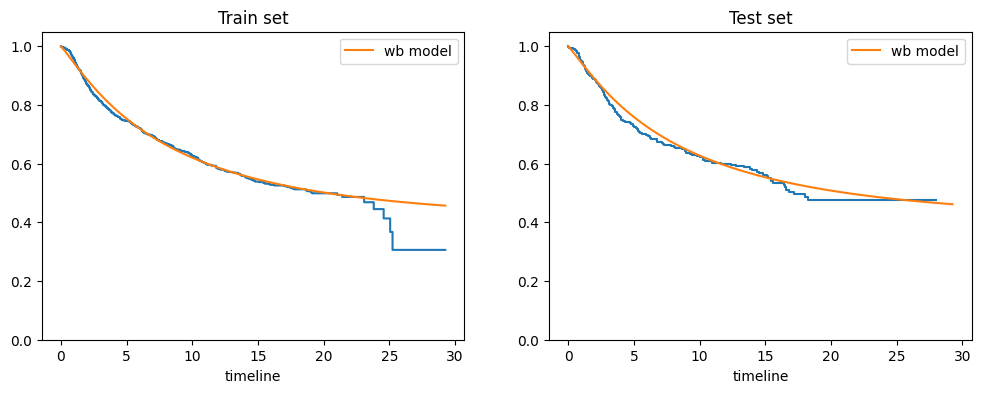

In [7]:
ts_grid = wb_summary["ts_grid"].flatten()

wb_S_ts_train = wb_summary["S_ts_train"]
wb_S_ts_train_avg = np.mean( wb_S_ts_train, axis = 1 )
wb_S_ts_test = wb_summary["S_ts_test"]
wb_S_ts_test_avg = np.mean( wb_S_ts_test, axis = 1 )

fig, ax = plt.subplots(nrows = 1, ncols = 2, figsize = (12,4))

km_train = lifelines.KaplanMeierFitter()
km_train.fit(y_train, delta_train)
km_train.plot(ax = ax[0], ci_show = False, show_censors = False, legend = False, label = '_')

# for j in range(500):
#     ax[0].plot(ts_grid, wb_S_ts_train[:,j], alpha = 0.05, color = "black")
ax[0].plot(ts_grid, wb_S_ts_train_avg, label = "wb model")
ax[0].set_ylim(0, 1.05)
ax[0].legend()
ax[0].set_title("Train set")

km_test = lifelines.KaplanMeierFitter()
km_test.fit(y_test, delta_test)
km_test.plot(ax = ax[1], ci_show = False, show_censors = False, legend = False, label = '_')
    
ax[1].plot(ts_grid, wb_S_ts_test_avg, label = "wb model")
ax[1].set_ylim(0, 1.05)
ax[1].legend()
ax[1].set_title("Test set")

plt.show()

In [8]:
pd.options.display.float_format = '{:.6f}'.format
mu_colnames = list( np.char.add("mu_", list(z_train_mu.columns)) )

colnames = mu_colnames + ["sigma", "p"]

display( cure_aft.summary_betas(wb_model, colnames) )

pd.options.display.float_format = None

,Coef,Se,Z,pvalue,CI(95%)
mu_const,2.618792,0.102363,25.583477,0.000000,(2.4182 ; 2.8194)
mu_age_at_diagnosis,-0.011519,0.054703,-0.210570,0.833223,(-0.1187 ; 0.0957)
mu_npi,-0.377875,0.057436,-6.579050,0.000000,(-0.4904 ; -0.2653)
mu_pam50_subtype_Basal,-1.156444,0.193668,-5.971281,0.000000,(-1.536 ; -0.7769)
mu_pam50_subtype_Her2,-0.877525,0.175668,-4.995355,0.000001,(-1.2218 ; -0.5332)
mu_pam50_subtype_LumB,-0.514047,0.136370,-3.769507,0.000164,(-0.7813 ; -0.2468)
mu_pam50_subtype_Normal,-0.469581,0.208901,-2.247865,0.024585,(-0.879 ; -0.0601)
mu_pam50_subtype_claudin-low,0.066905,0.288696,0.231749,0.816733,(-0.4989 ; 0.6327)
sigma,0.892899,0.038367,23.272556,0.000000,(0.8208 ; 0.9714)
p,0.410850,0.027665,14.851010,0.000000,(0.3579 ; 0.4659)


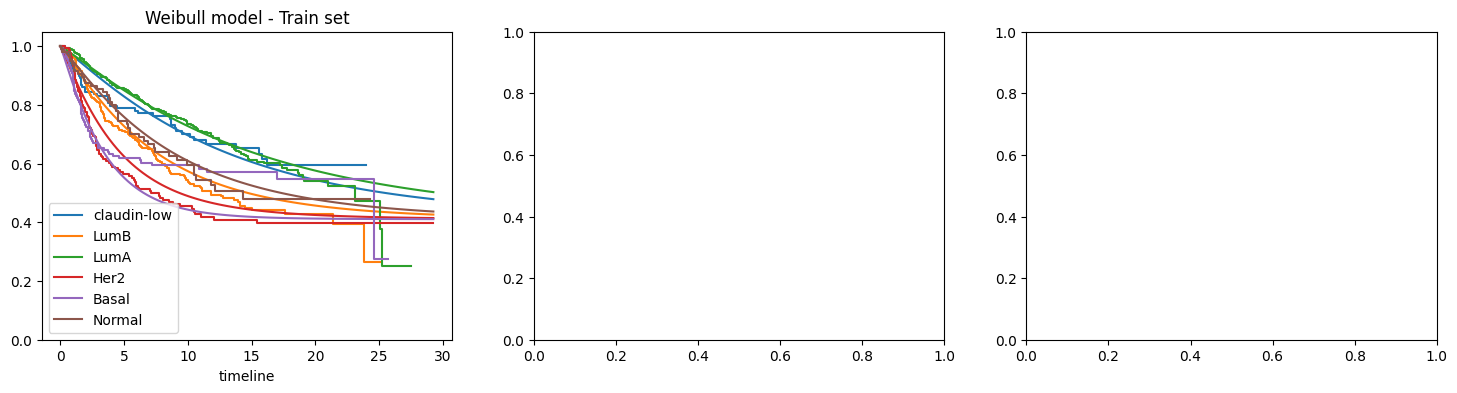

In [9]:
fig, ax = plt.subplots(nrows = 1, ncols = 3, figsize = (18,4))

colors = plt.rcParams['axes.prop_cycle'].by_key()['color']
ts_grid = wb_summary["ts_grid"].flatten()
wb_S_ts_train = wb_summary["S_ts_train"].numpy()
# ln_S_ts_train = ln_summary["S_ts_train"].numpy()
# ll_S_ts_train = ll_summary["S_ts_train"].numpy()

unique_pam50_subtypes = df_clean_train["pam50_subtype"].unique()

for i, subtype in enumerate(unique_pam50_subtypes):
    subtype_patients = df_clean_train["pam50_subtype"] == subtype
    time = df_clean_train.loc[subtype_patients, "time"] / 12
    delta = df_clean_train.loc[subtype_patients, "delta"]

    wb_S_ts_train_subtype_avg = np.mean(wb_S_ts_train[:, subtype_patients], axis = 1)
    # ln_S_ts_train_subtype_avg = np.mean(ln_S_ts_train[:, subtype_patients], axis = 1)
    # ll_S_ts_train_subtype_avg = np.mean(ll_S_ts_train[:, subtype_patients], axis = 1)

    ax[0].plot(ts_grid, wb_S_ts_train_subtype_avg, color = colors[i])
    # ax[1].plot(ts_grid, ln_S_ts_train_subtype_avg, color = colors[i])
    # ax[2].plot(ts_grid, ll_S_ts_train_subtype_avg, color = colors[i])
    
    km = lifelines.KaplanMeierFitter()
    km.fit(time, delta)
    km.plot(ax = ax[0], ci_show = False, show_censors = False, label = subtype)
    # km.plot(ax = ax[1], ci_show = False, show_censors = False, label = subtype)
    # km.plot(ax = ax[2], ci_show = False, show_censors = False, label = subtype)

ax[0].set_title("Weibull model - Train set")
ax[0].set_ylim(0, 1.05)
# ax[1].set_title("Log-normal model - Train set")
# ax[1].set_ylim(0, 1.05)
# ax[2].set_title("Log-logistic model - Train set")
# ax[2].set_ylim(0, 1.05)

plt.show()